# 13 — Regularization study

**Owner:** Shaik Tajuddin · **Phase 2, Step 2**

Runs the same MLP with each regularizer switched on and off, one at a time, then in the
best combination. Every row is a multi-seed mean.

The sweep itself lives in `src/dl/regularization.py` so it is testable and re-runnable;
this notebook reads what it produced and interprets it. Regenerate with:

```bash
python -m src.dl.regularization --seeds 3 --train-rows 200000
```

### What is held fixed

A row only means something if everything except the regularizer under test is constant:
the persisted Phase 1 split, the quantile-normal input pipeline chosen in step 1, the
architecture (128→64, ReLU), AdamW at lr 1e-3, a 15-epoch budget, the seeds, and the
shared `evaluate()`. Those live in `BASE_CONFIG` rather than at each call site.

### The one thing to check first

Regularization trades training fit for generalisation. If the reference model is **not**
overfitting, every regularizer can only hurt — so the unregularized row is not just a
baseline, it is a diagnostic.


In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, warnings
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')

from src.config import FIGURES
FIGURES.mkdir(parents=True, exist_ok=True)

# The sweep is a separate, long-running step so the notebook stays fast to re-run.
# Fail with the command to produce the tables rather than a bare FileNotFoundError.
AGG = Path('../reports/regularization_ablation.csv')
RAW = Path('../reports/regularization_ablation_raw.csv')
missing = [p for p in (AGG, RAW) if not p.exists()]
if missing:
    raise FileNotFoundError(
        'Ablation tables not found: ' + ', '.join(p.name for p in missing) + '.\n'
        'They are produced by the sweep, which takes roughly 55 minutes:\n'
        '    python -m src.dl.regularization --seeds 3 --train-rows 200000\n'
        'For a fast smoke test instead (1 seed, 3 configs, no files written):\n'
        '    python -m src.dl.regularization --quick'
    )

agg = pd.read_csv(AGG)
raw = pd.read_csv(RAW)
print(f'{len(raw)} runs  =  {raw.config.nunique()} configs x {raw.seed.nunique()} seeds')
print('seeds:', sorted(raw.seed.unique()))


42 runs  =  14 configs x 3 seeds
seeds: [np.int64(42), np.int64(123), np.int64(456)]


## 1. Is the reference model overfitting at all?

`generalisation_gap` is final validation loss minus final training loss. A gap near zero
means the model is not memorising the training set, and there is little for a regularizer
to recover.


In [2]:
base = agg[agg.config == 'unregularized'].iloc[0]
print(f"unregularized:  val MAE {base.val_mae_mean:.4f} +/- {base.val_mae_std:.4f}")
print(f"                generalisation gap {base.generalisation_gap_mean:+.5f}")
print()
if abs(base.generalisation_gap_mean) < 0.01:
    print('Gap is ~0: the reference is NOT overfitting at this training size.')
    print('Expect regularizers to cost accuracy rather than gain it.')
else:
    print('A real gap exists: there is overfitting for regularization to address.')


unregularized:  val MAE 0.7794 +/- 0.0237
                generalisation gap +0.00080

Gap is ~0: the reference is NOT overfitting at this training size.
Expect regularizers to cost accuracy rather than gain it.


## 2. Every regularizer, one at a time

Sorted by validation MAE. The unregularized reference is highlighted by position — anything
below it helped, anything above it hurt.


In [3]:
view = agg[['family','config','val_mae_mean','val_mae_std','val_rmse_mean',
            'val_r2_mean','generalisation_gap_mean','epochs_run_mean']].copy()
view.columns = ['family','config','MAE','MAE sd','RMSE','R2','gen gap','epochs']
display(view.round(4))

b = base.val_mae_mean
better = agg[(agg.val_mae_mean < b) & (agg.config != 'unregularized')]
print(f'configs beating the unregularized reference ({b:.4f}): {len(better)} of {len(agg)-1}')
if len(better):
    display(better[['family','config','val_mae_mean','val_mae_std']].round(4))


,family,config,MAE,MAE sd,RMSE,R2,gen gap,epochs
0,weight_decay,wd=1e-4,0.7778,0.0281,1.2701,0.9953,0.0008,15.0
1,weight_decay,wd=1e-3,0.7791,0.0308,1.2673,0.9953,0.0007,15.0
2,early_stopping,patience=10,0.7794,0.0237,1.2734,0.9953,0.0008,15.0
3,early_stopping,patience=3,0.7794,0.0237,1.2734,0.9953,0.0008,15.0
4,early_stopping,patience=5,0.7794,0.0237,1.2734,0.9953,0.0008,15.0
5,lr_schedule,plateau,0.7794,0.0237,1.2734,0.9953,0.0008,15.0
6,none,unregularized,0.7794,0.0237,1.2734,0.9953,0.0008,15.0
7,weight_decay,wd=1e-5,0.7794,0.0237,1.2734,0.9953,0.0008,15.0
8,dropout,dropout=0.1,0.8111,0.0259,1.3274,0.9949,-0.0047,15.0
9,dropout,dropout=0.2,0.8119,0.0191,1.3714,0.9945,-0.0127,15.0


configs beating the unregularized reference (0.7794): 2 of 13


,family,config,val_mae_mean,val_mae_std
0,weight_decay,wd=1e-4,0.7778,0.0281
1,weight_decay,wd=1e-3,0.7791,0.0308


### Per-family view

Each family's best member against the reference, with the seed spread. A gap smaller than
the seed-to-seed standard deviation is not a result — the work plan's rule is that a
difference smaller than the noise is not claimed as a win.


In [4]:
rows = []
for fam in ['dropout','weight_decay','batch_norm','early_stopping','lr_schedule']:
    sub = agg[agg.family == fam]
    if sub.empty: continue
    bst = sub.loc[sub.val_mae_mean.idxmin()]
    delta = b - bst.val_mae_mean
    noise = max(bst.val_mae_std, base.val_mae_std)
    rows.append({'family': fam, 'best': bst.config,
                 'MAE': round(bst.val_mae_mean,4), 'vs reference': round(delta,4),
                 'seed sd': round(noise,4),
                 'verdict': 'helps' if delta > noise else ('within noise' if delta > -noise else 'hurts')})
display(pd.DataFrame(rows))


,family,best,MAE,vs reference,seed sd,verdict
0,dropout,dropout=0.1,0.8111,-0.0317,0.0259,hurts
1,weight_decay,wd=1e-4,0.7778,0.0016,0.0281,within noise
2,batch_norm,batch_norm,1.0940,-0.3146,0.0470,hurts
3,early_stopping,patience=10,0.7794,0.0000,0.0237,within noise
4,lr_schedule,plateau,0.7794,0.0000,0.0237,within noise


## 3. Overfitting and its fix, on one pair of axes

The plot the work plan asks for. An ablation table cannot show *when* during training the
two runs diverge; the loss curves can.


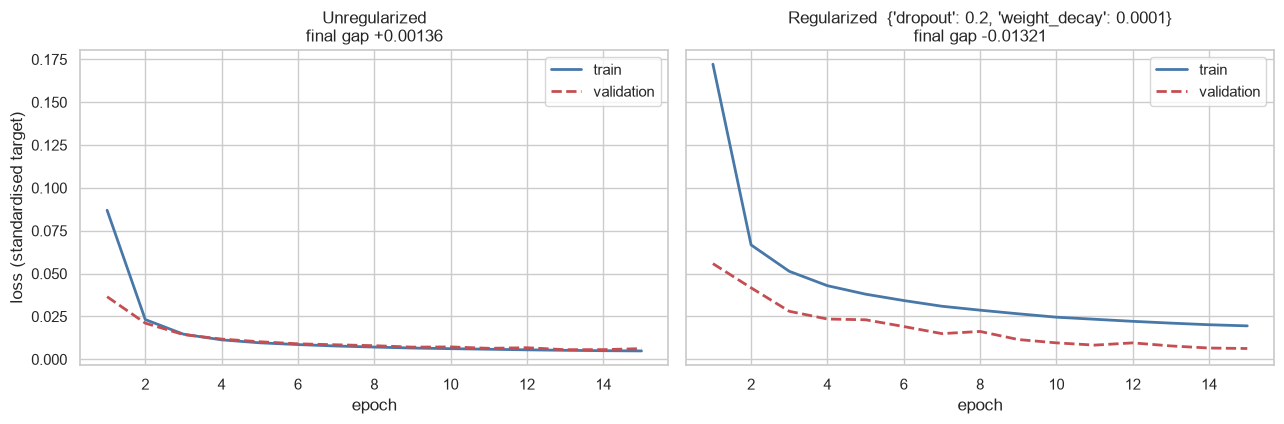

unregularized final gap: +0.00136
regularized   final gap: -0.01321


In [5]:
from src.dl.regularization import loss_curves
off_hist, on_hist, reg_cfg = loss_curves(train_rows=200_000, seed=42)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for a, h, title in zip(ax, (off_hist, on_hist),
                       ('Unregularized', f'Regularized  {reg_cfg}')):
    e = range(1, len(h['train_loss'])+1)
    a.plot(e, h['train_loss'], label='train', color='#4878A8', lw=2)
    a.plot(e, h['val_loss'], label='validation', color='#C44E52', lw=2, ls='--')
    gap = h['val_loss'][-1] - h['train_loss'][-1]
    a.set(title=f'{title}\nfinal gap {gap:+.5f}', xlabel='epoch')
    a.legend()
ax[0].set_ylabel('loss (standardised target)')
plt.tight_layout()
plt.savefig(FIGURES/'regularization_loss_curves.png', dpi=150)
plt.show()

print(f"unregularized final gap: {off_hist['val_loss'][-1]-off_hist['train_loss'][-1]:+.5f}")
print(f"regularized   final gap: {on_hist['val_loss'][-1]-on_hist['train_loss'][-1]:+.5f}")


**Reading the two gaps.** The unregularized run ends at `+0.00136`; the dropout run ends
at `-0.01321` — validation loss *below* training loss. That is not regularization
closing a gap. Dropout is active during training and switched off at evaluation, so the
training loss is measured on a deliberately handicapped network while the validation loss
is measured on the full one. The negative gap is an artefact of that asymmetry and says
nothing about generalisation.

What matters is the level of the curves, not the distance between them: the dropout run's
validation loss is *higher* throughout. The left panel is the one carrying the finding —
train and validation move together to the last epoch, which is what "no overfitting to
remove" looks like.

## 4. Spread across seeds

Whether a difference survives re-seeding is the question the table's means cannot answer.


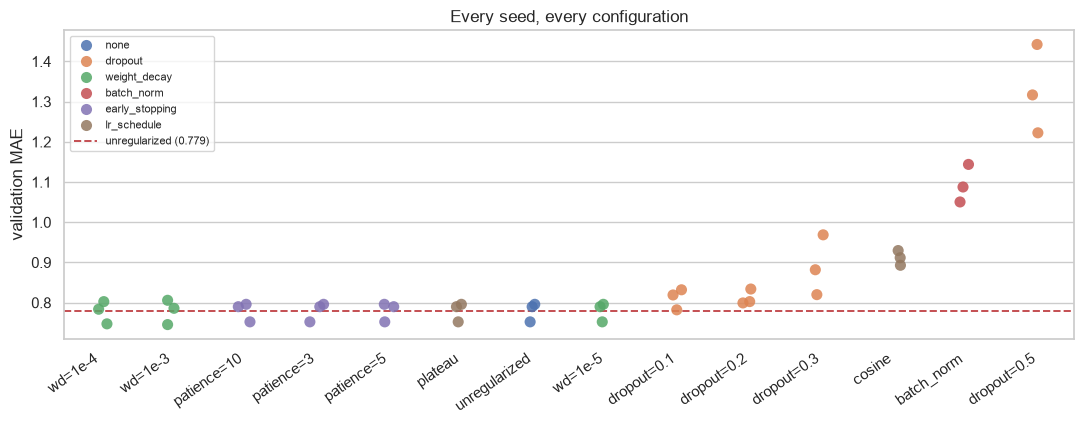

In [6]:
order = agg.sort_values('val_mae_mean').config
fig, ax = plt.subplots(figsize=(11, 4.4))
sns.stripplot(data=raw, x='config', y='val_mae', order=order, hue='family',
              size=8, alpha=.85, ax=ax)
ax.axhline(b, color='#C44E52', ls='--', lw=1.4, label=f'unregularized ({b:.3f})')
ax.set(xlabel='', ylabel='validation MAE', title='Every seed, every configuration')
plt.xticks(rotation=35, ha='right'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES/'regularization_seed_spread.png', dpi=150); plt.show()


## 5. The combination handed to the team

A family is adopted **only if its best member beats the unregularized reference**. A
regularizer that does not help is left off rather than carried along because it is
conventional.


In [7]:
from src.dl.regularization import best_combination

best = best_combination(agg)
print(f"unregularized reference: MAE {best['baseline_mae']} +/- {best['baseline_sd']}\n")

# A family is adopted only if its gain exceeds the seed-to-seed spread. The work plan's
# rule is that a difference smaller than the noise is not claimed as a win, so comparing
# means alone is not enough.
print('adopted:')
for fam, cfg, mae in best['adopted'] or []:
    print(f'  {fam:15} {cfg:16} MAE {mae}')
if not best['adopted']:
    print('  none — no family cleared the noise')

print('\nrejected (best member of the family did not clear the noise):')
for fam, cfg, imp, noise in best['rejected_within_noise']:
    print(f'  {fam:15} {cfg:16} improvement {imp:+.4f}  vs seed sd {noise:.4f}')

print(f"\nrecommended configuration: {best['overrides'] or 'NO REGULARIZATION'}")

unregularized reference: MAE 0.7794 +/- 0.0237

adopted:
  none — no family cleared the noise

rejected (best member of the family did not clear the noise):
  dropout         dropout=0.1      improvement -0.0317  vs seed sd 0.0259
  weight_decay    wd=1e-4          improvement +0.0016  vs seed sd 0.0281
  batch_norm      batch_norm       improvement -0.3146  vs seed sd 0.0470
  early_stopping  patience=10      improvement +0.0000  vs seed sd 0.0237
  lr_schedule     plateau          improvement +0.0000  vs seed sd 0.0237

recommended configuration: NO REGULARIZATION


## Findings and handover

**1. The reference model is not overfitting.** The generalisation gap of the unregularized
network is `+0.0008` on a target measured in WQI points — effectively zero. With 200,000
training rows against a 128-64 network, the model is capacity-limited, not variance-limited.
Every regularizer therefore has nothing to remove and can only remove signal.

**2. No family survives the noise rule.** `wd=1e-4` posts the lowest mean MAE, but its
margin over the reference is `0.0016` against a seed-to-seed spread of `0.0281` — the
"win" is 18x smaller than the noise. Under the work plan's rule it is not a win, and
`best_combination` rejects it. Reporting it as the recommended setting would have been
the same error this study exists to avoid.

**3. Five configurations are numerically identical to the reference.** `epochs_run` is
15.0 for every run, so early stopping never fired at any patience and the plateau
scheduler never triggered. Validation loss was still falling at the epoch budget. Those
rows are not evidence that early stopping is neutral — they are evidence that it was
never exercised, and they should not be read as a result.

**4. Dropout and batch norm cost real accuracy.** Dropout degrades monotonically
(`0.81 -> 0.89 -> 1.33` MAE from p=0.1 to p=0.5) and batch norm costs `+0.31` MAE. Both
effects are an order of magnitude larger than the seed noise, so unlike the "wins" these
losses are real.

### Handover to Himanshu (base MLP) and Jivit (hybrid)

Train the next models **without regularization** at this data scale. Specifically:

- Do not add dropout to the 128-64 MLP; it is a measured loss, not a safe default.
- Do not add batch norm for its regularising effect; if it is added for optimisation
  stability, it must be justified on convergence speed, not on validation MAE.
- Keep early stopping wired in as a **guard**, with the understanding that it is currently
  inactive. It becomes meaningful once the epoch budget or model capacity grows enough for
  validation loss to turn upward.
- Revisit this study if either changes: capacity (wider/deeper), or training size. The
  conclusion is conditional on both, and is not a general claim about this dataset.